นาย อัญญาฤทธิ์ จ๊ะราจา 670510777 โฟล์ค 0824777935

# Detectron2's Panoptic FPN (Feature Pyramid Network, a multi-scale feature extractor)

- Building a pyramid of features from a convolutional neural network (like ResNet).
- Combining low-level, high-resolution features (good for small objects) with high-level, semantic features (good for large objects).
- Allowing the model to detect and segment objects across different scales more effectively.

ถอดโค้ดตามภาพตัวอย่างสำหรับ Google Colab ให้รันเซลล์จากบนลงล่าง โดยใช้ URL รูปแมวตามต้นฉบับ หรือกำหนด `IMG_PATH` เพื่อใช้รูปของคุณเอง ชื่อโฟลเดอร์ที่ถูกปิดไว้ในภาพใช้เป็น `Colab Notebooks/` แทน กรุณาแก้ `folder_path` ตามต้องการ

ไฟล์นี้ยังไม่มีผลรันโมเดล ค่า segments และสีของภาพอาจต่างจากตัวอย่างเมื่อรันจริง การติดตั้ง Detectron2 จะ build จาก source และต้องใช้ PyTorch/torchvision ที่เข้ากันได้ ดู [คู่มือติดตั้ง Detectron2](https://detectron2.readthedocs.io/en/latest/tutorials/install.html)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
folder_path = '/content/drive/MyDrive/Colab Notebooks/ImgProc/Images/'

In [ ]:
%pip -q install torch torchvision pillow matplotlib numpy requests opencv-python ninja setuptools wheel
%pip -q install --no-build-isolation 'git+https://github.com/facebookresearch/detectron2.git'

  Preparing metadata (setup.py) ... done


In [ ]:
import torch, numpy as np, matplotlib.pyplot as plt, requests, io, os
from PIL import Image
import cv2

from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import Visualizer

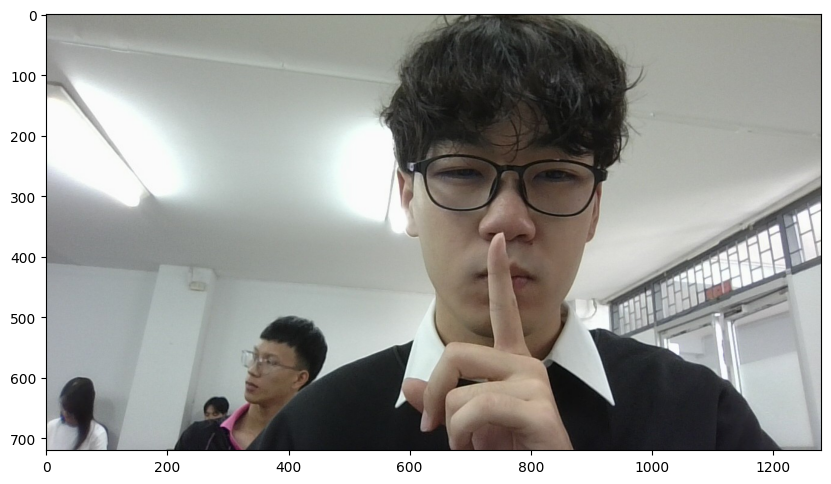

In [ ]:
IMG_PATH = "sui.jpg"

img_pil = Image.open(os.path.join(folder_path, IMG_PATH))
plt.figure(figsize=(10,10))
plt.imshow(img_pil)
plt.show()

In [ ]:
img_rgb = np.array(img_pil)
img_bgr = img_rgb[:, :, ::-1].copy()

In [ ]:
# ==== Detectron2 config: Panoptic FPN ====
cfg = get_cfg()

cfg_files = ["COCO-PanopticSegmentation/panoptic_fpn_R_50_3x.yaml",
             "COCO-PanopticSegmentation/panoptic_fpn_R_50_1x.yaml",
             "COCO-PanopticSegmentation/panoptic_fpn_R_101_3x.yaml"]
cfgF = 1

cfg.merge_from_file(model_zoo.get_config_file(
    cfg_files[cfgF]
))
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
    cfg_files[cfgF]
)
cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

predictor = DefaultPredictor(cfg)

In [ ]:
# ==== Inference ====
outputs = predictor(img_bgr)
# "panoptic_seg" is a tuple: (panoptic_map [H,W], segments_info [list of dict])
pan_map, segments_info = outputs["panoptic_seg"]
pan_map = pan_map.to("cpu")

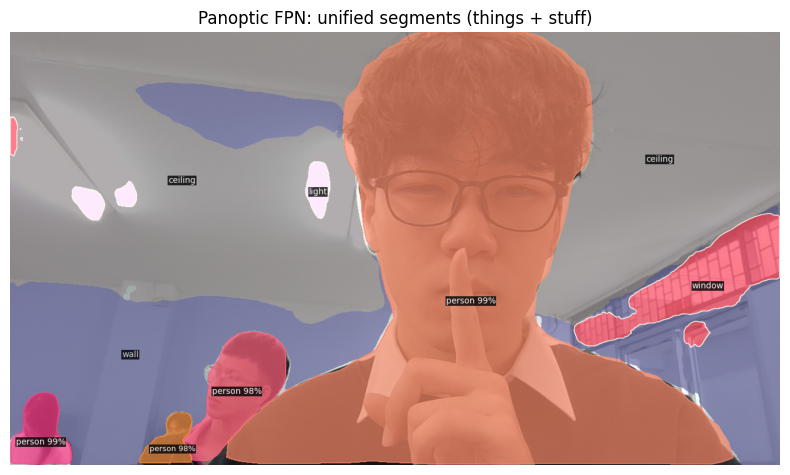

In [ ]:
# ==== METADATA FIX (Detectron2 Visualizer) ====
from detectron2.data import MetadataCatalog
import detectron2.data.datasets # ensures built-in datasets are registered

# If your cfg has no TEST dataset, explicitly take the COCO panoptic metadata:
if len(cfg.DATASETS.TEST):
    meta = MetadataCatalog.get(cfg.DATASETS.TEST[0])
else:
    # use the standard COCO-2017 panoptic "separated" metadata
    meta = MetadataCatalog.get("coco_2017_val_panoptic_separated")

viz = Visualizer(img_rgb, metadata=meta)
drawn = viz.draw_panoptic_seg_predictions(pan_map, segments_info)
plt.figure(figsize=(8,8)); plt.imshow(drawn.get_image()); plt.axis("off")
plt.title("Panoptic FPN: unified segments (things + stuff)")
plt.tight_layout()
os.makedirs(folder_path, exist_ok=True)
plt.savefig(os.path.join(folder_path, "panoptic_result.png"))
plt.show()

In [ ]:
print("First few segments:")
for s in segments_info[:10]:
    print(s)

First few segments:
{'id': 1, 'isthing': True, 'score': 0.9946569204330444, 'category_id': 0, 'instance_id': 0, 'area': 302498.0}
{'id': 2, 'isthing': True, 'score': 0.9877205491065979, 'category_id': 0, 'instance_id': 1, 'area': 8439.0}
{'id': 3, 'isthing': True, 'score': 0.9788976907730103, 'category_id': 0, 'instance_id': 2, 'area': 4604.0}
{'id': 4, 'isthing': True, 'score': 0.9779324531555176, 'category_id': 0, 'instance_id': 3, 'area': 19636.0}
{'id': 5, 'isthing': False, 'category_id': 13, 'area': 6066.0}
{'id': 6, 'isthing': False, 'category_id': 36, 'area': 29858.0}
{'id': 7, 'isthing': False, 'category_id': 39, 'area': 367738.0}
{'id': 8, 'isthing': False, 'category_id': 52, 'area': 174825.0}


In [ ]:
segments_info

[{'id': 1,
  'isthing': True,
  'score': 0.9946569204330444,
  'category_id': 0,
  'instance_id': 0,
  'area': 302498.0},
 {'id': 2,
  'isthing': True,
  'score': 0.9877205491065979,
  'category_id': 0,
  'instance_id': 1,
  'area': 8439.0},
 {'id': 3,
  'isthing': True,
  'score': 0.9788976907730103,
  'category_id': 0,
  'instance_id': 2,
  'area': 4604.0},
 {'id': 4,
  'isthing': True,
  'score': 0.9779324531555176,
  'category_id': 0,
  'instance_id': 3,
  'area': 19636.0},
 {'id': 5, 'isthing': False, 'category_id': 13, 'area': 6066.0},
 {'id': 6, 'isthing': False, 'category_id': 36, 'area': 29858.0},
 {'id': 7, 'isthing': False, 'category_id': 39, 'area': 367738.0},
 {'id': 8, 'isthing': False, 'category_id': 52, 'area': 174825.0}]